# 03 — Obfuskasiya olunmuş test dəsti

**Sual:** 99%+ nəticə göstərən detektorlar eyni hücumun obfuskasiya olunmuş formasını tanıyırmı?

- Modellər: `02_baseline_models_v2.ipynb`-də öyrədilmiş LR (əsas), Linear SVM, RF, Multinomial NB (`clean_v2`).
- Obfuskasiya yalnız **test dəstinin zərərli sorğularına** tətbiq olunur; train/val-a toxunulmur, modellər yenidən öyrədilmir.
- Texnikalar `src/obfuscation.py` modulundadır, hər biri ayrıca funksiyadır. Seed = 42.
- Texnika sorğunu dəyişmirsə (məs. sorğuda boşluq yoxdur), həmin sətir o texnikanın dəstindən çıxarılır.
- Hər texnika üçün recall həm obfuskasiyadan **əvvəl**, həm **sonra** eyni sətirlər üzərində hesablanır —
  beləliklə düşüş yalnız obfuskasiyanın təsirini göstərir, alt dəstin fərqli tərkibini yox.

## 0. Mühit, modellər və test dəsti

In [1]:
import random
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import obfuscation as obf

PROC_DIR = ROOT / "data" / "processed"
FIG_DIR = ROOT / "figures"
RES_DIR = ROOT / "results"
MODEL_DIR = ROOT / "models"

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e5e4e0",
    "grid.linewidth": 0.6,
    "axes.axisbelow": True,
    "axes.edgecolor": "#8a8984",
    "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
})

def save_fig(fig, name):
    fig.savefig(FIG_DIR / name, dpi=300, bbox_inches="tight")

MODELS = {
    "LR": joblib.load(MODEL_DIR / "lr_v2.joblib"),
    "SVM": joblib.load(MODEL_DIR / "svm_v2.joblib"),
    "RF": joblib.load(MODEL_DIR / "rf_v2.joblib"),
    "NB": joblib.load(MODEL_DIR / "nb_v2.joblib"),
}
MODEL_COLORS = {"LR": "#2a78d6", "SVM": "#eb6834", "RF": "#1baf7a", "NB": "#eda100"}
lr = MODELS["LR"]

test = pd.read_csv(PROC_DIR / "test_v2.csv", keep_default_na=False, dtype={"Query": str, "Label": int})
malicious = test.loc[test.Label == 1, "Query"].reset_index(drop=True)
print(f"Test dəsti: {len(test)} sətir, zərərli: {len(malicious)}")

Test dəsti: 4539 sətir, zərərli: 1745


## 1. Texnikalar
`keyword_split_comment` (`UN/**/ION`) **MySQL-də sintaktik olaraq etibarsızdır**: şərh token ayırıcısı kimi işləyir,
`UN/**/ION` iki ayrı identifikator kimi oxunur və sorğu xəta verir. Bu texnika yalnız detektor testi üçündür —
real hücum kimi işləmir. Kombinasiyada bu texnika istifadə olunmur.

### Təhdid modeli: detektor harada dayanır?
- **Ssenari A — middleware (real ssenari).** Detektor framework sorğu parametrlərini **bir dəfə** decode etdikdən
  sonra işləyir (Express `req.query`). Modelə `urllib.parse.unquote(payload)` verilir. Nəticədə `url_encode`
  orijinal payload-a, `alt_whitespace_url` (`%0a`) isə həqiqi `\n`-ə, yəni `alt_whitespace`-ə çevrilir.
- **Ssenari B — xam trafik** (log analizi, şəbəkə səviyyəsində WAF). Payload olduğu kimi modelə verilir.

`mysql_valid` payload-ın hədəfə çatdıqdan sonra MySQL-də hücum kimi işləyib-işləmədiyini göstərir:
- `yes` — bir dəfə decode olunmuş forma işlək SQL-dir
- `conditional` — `double_url_encode` (və onu ehtiva edən kombinasiyalar): bir decode-dan sonra hələ `%27` qalır,
  yalnız tətbiq **ikinci dəfə** decode edərsə işləyir (nadir hal)
- `no` — `keyword_split_comment`: sintaktik olaraq etibarsızdır

Qeyd: `unquote` `+` simvolunu boşluğa çevirmir (form-encoding qaydası); payload-larda `+` SQL operatoru kimi
işləndiyi üçün bu seçim saxlanılıb.

In [2]:
DESCRIPTIONS = {
    "random_case": "Təsadüfi böyük-kiçik hərf: UnIoN SeLeCt",
    "inline_comment_space": "Boşluq → inline şərh: UNION/**/SELECT",
    "alt_whitespace": "Boşluq → tab / LF / CR / VT / FF (xam simvol)",
    "alt_whitespace_url": "Boşluq → %09 / %0a / %0d",
    "url_encode": "URL encoding: ' → %27",
    "double_url_encode": "İkiqat URL encoding: ' → %2527",
    "versioned_comment": "MySQL versiyalı şərh: /*!50000UNION*/",
    "logical_operator": "OR → ||, AND → &&",
    "hex_strings": "String literal → hex: 'admin' → 0x61646d696e",
    "keyword_split_comment": "Açar söz daxilində şərh: UN/**/ION (MySQL-də etibarsız)",
    "combination": "Təsadüfi 2–3 etibarlı texnika birlikdə",
}
TECH_ORDER = list(obf.TECHNIQUES) + ["combination"]
from urllib.parse import unquote

def mysql_validity(techniques):
    used = techniques.split("+")
    if any(t in obf.SYNTACTICALLY_INVALID for t in used):
        return "no"
    if "double_url_encode" in used:
        return "conditional"
    return "yes"

TECH_VALIDITY = {t: ("conditional (bəzi kombinasiyalar)" if t == "combination" else mysql_validity(t))
                 for t in TECH_ORDER}
display(pd.DataFrame({
    "technique": TECH_ORDER,
    "description": [DESCRIPTIONS[t] for t in TECH_ORDER],
    "mysql_valid": [TECH_VALIDITY[t] for t in TECH_ORDER],
}))

,technique,description,mysql_valid
0,random_case,Təsadüfi böyük-kiçik hərf: UnIoN SeLeCt,yes
1,inline_comment_space,Boşluq → inline şərh: UNION/**/SELECT,yes
2,alt_whitespace,Boşluq → tab / LF / CR / VT / FF (xam simvol),yes
3,alt_whitespace_url,Boşluq → %09 / %0a / %0d,yes
4,url_encode,URL encoding: ' → %27,yes
5,double_url_encode,İkiqat URL encoding: ' → %2527,conditional
6,versioned_comment,MySQL versiyalı şərh: /*!50000UNION*/,yes
7,logical_operator,"OR → ||, AND → &&",yes
8,hex_strings,String literal → hex: 'admin' → 0x61646d696e,yes
9,keyword_split_comment,Açar söz daxilində şərh: UN/**/ION (MySQL-də e...,no


## 2. Obfuskasiyanın tətbiqi
Hər texnika bütün zərərli test sorğularına ayrıca tətbiq olunur. Dəyişməyən sətirlər çıxarılır;
neçə sətrin qaldığı aşağıdakı cədvəldədir. Bütün obfuskasiya olunmuş sorğular 4-cü mərhələdə (real MySQL testi)
istifadə üçün `data/processed/obfuscated_test_v2.csv` faylına yazılır.

In [3]:
frames = []
for tech in TECH_ORDER:
    rows = pd.DataFrame(obf.apply_technique(tech, malicious, seed=SEED))
    rows.insert(0, "technique", tech)
    frames.append(rows)
all_rows = pd.concat(frames, ignore_index=True)

coverage = all_rows.groupby("technique", sort=False).agg(total=("changed", "size"), kept=("changed", "sum"))
coverage["dropped"] = coverage["total"] - coverage["kept"]
coverage["kept_pct"] = (coverage["kept"] / coverage["total"] * 100).round(1)
display(coverage)

obf_df = all_rows[all_rows.changed].drop(columns="changed").reset_index(drop=True)
obf_df["mysql_valid"] = obf_df["techniques"].map(mysql_validity)

# Hər payload iki ssenaridə: A — bir dəfə decode olunmuş, B — xam
SCENARIOS = {"A": "A — middleware (bir dəfə decode)", "B": "B — xam trafik"}
long_df = pd.concat([
    obf_df.assign(scenario="A", model_input=obf_df["obfuscated"].map(unquote),
                  original_input=obf_df["original"].map(unquote)),
    obf_df.assign(scenario="B", model_input=obf_df["obfuscated"], original_input=obf_df["original"]),
], ignore_index=True)
long_df["same_as_original"] = long_df["model_input"] == long_df["original_input"]
long_df.to_csv(PROC_DIR / "obfuscated_test_v2.csv", index=False, encoding="utf-8")
print(f"obfuscated_test_v2.csv: {len(long_df)} sətir ({len(obf_df)} payload × 2 ssenari)")
print("\nmysql_valid bölgüsü:")
display(obf_df.groupby(["technique", "mysql_valid"], sort=False).size().unstack(fill_value=0))
print("Ssenari A-da orijinal ilə eyniləşən payload-lar (texnika üzrə):")
display(long_df[long_df.scenario == "A"].groupby("technique", sort=False)["same_as_original"].mean()
        .mul(100).round(1).rename("A-da orijinala bərabər, %"))

print("\nKombinasiyada istifadə olunan texnika dəstləri (ən çox 10):")
display(obf_df.loc[obf_df.technique == "combination", "techniques"].value_counts().head(10))

,total,kept,dropped,kept_pct
technique,,,,
random_case,1745,1714,31,98.2
inline_comment_space,1745,1732,13,99.3
alt_whitespace,1745,1732,13,99.3
alt_whitespace_url,1745,1732,13,99.3
url_encode,1745,1740,5,99.7
double_url_encode,1745,1740,5,99.7
versioned_comment,1745,1714,31,98.2
logical_operator,1745,1070,675,61.3
hex_strings,1745,628,1117,36.0


obfuscated_test_v2.csv: 34310 sətir (17155 payload × 2 ssenari)

mysql_valid bölgüsü:


mysql_valid,yes,conditional,no
technique,,,
random_case,1714,0,0
inline_comment_space,1732,0,0
alt_whitespace,1732,0,0
alt_whitespace_url,1732,0,0
url_encode,1740,0,0
double_url_encode,0,1740,0
versioned_comment,1714,0,0
logical_operator,1070,0,0
hex_strings,628,0,0


Ssenari A-da orijinal ilə eyniləşən payload-lar (texnika üzrə):


technique
random_case               0.0
inline_comment_space      0.0
alt_whitespace            0.0
alt_whitespace_url        0.0
url_encode               99.9
double_url_encode         0.0
versioned_comment         0.0
logical_operator          0.0
hex_strings               0.0
keyword_split_comment     0.0
combination               1.9
Name: A-da orijinala bərabər, %, dtype: float64


Kombinasiyada istifadə olunan texnika dəstləri (ən çox 10):


techniques
hex_strings+versioned_comment                     65
hex_strings+random_case                           65
logical_operator+versioned_comment                53
logical_operator+random_case                      53
random_case+versioned_comment                     50
logical_operator+hex_strings                      49
versioned_comment+alt_whitespace                  43
logical_operator+alt_whitespace                   42
logical_operator+hex_strings+versioned_comment    42
logical_operator+hex_strings+random_case          39
Name: count, dtype: int64

## 3. Qiymətləndirmə: hər texnika üzrə recall, iki ssenaridə
Bütün sətirlər zərərli olduğundan, recall = aşkarlanan sorğuların payı. Hər (ssenari, texnika) üçün:
- `recall_before` — həmin sətirlərin **orijinal** formasında recall (həmin ssenarinin girişi ilə)
- `recall_after` — obfuskasiyadan sonra recall
- `drop_pp` = before − after (faiz bəndi)

LR üçün əlavə olaraq orta ehtimal (əvvəl/sonra) göstərilir. Hədd = 0.5.

In [4]:
# Hər unikal giriş üçün proqnozu bir dəfə hesablayırıq (A və B-də çox giriş təkrarlanır)
unique_inputs = pd.unique(pd.concat([long_df["model_input"], long_df["original_input"]]))
pred_cache = {m: dict(zip(unique_inputs, model.predict(unique_inputs))) for m, model in MODELS.items()}
p_cache = dict(zip(unique_inputs, lr.predict_proba(unique_inputs)[:, 1]))

for m in MODELS:
    long_df[f"pred_{m}"] = long_df["model_input"].map(pred_cache[m])
    long_df[f"pred_{m}_orig"] = long_df["original_input"].map(pred_cache[m])
long_df["p_lr_before"] = long_df["original_input"].map(p_cache)
long_df["p_lr_after"] = long_df["model_input"].map(p_cache)

result_rows = []
for sc in SCENARIOS:
    orig_inputs = malicious.map(unquote) if sc == "A" else malicious
    for m in MODELS:
        r = MODELS[m].predict(orig_inputs).mean()
        result_rows.append({"scenario": sc, "technique": "original", "model": m, "n_rows": len(malicious),
                            "mysql_valid": "yes", "same_as_original_pct": 100.0,
                            "recall_before": r, "recall_after": r})
    for tech in TECH_ORDER:
        sub = long_df[(long_df.scenario == sc) & (long_df.technique == tech)]
        for m in MODELS:
            result_rows.append({
                "scenario": sc, "technique": tech, "model": m, "n_rows": len(sub),
                "mysql_valid": TECH_VALIDITY[tech],
                "same_as_original_pct": sub["same_as_original"].mean() * 100,
                "recall_before": sub[f"pred_{m}_orig"].mean(),
                "recall_after": sub[f"pred_{m}"].mean(),
                "lr_mean_p_before": sub["p_lr_before"].mean() if m == "LR" else np.nan,
                "lr_mean_p_after": sub["p_lr_after"].mean() if m == "LR" else np.nan,
            })

results = pd.DataFrame(result_rows)
results["drop_pp"] = ((results["recall_before"] - results["recall_after"]) * 100).round(2)
for c in ["recall_before", "recall_after", "lr_mean_p_before", "lr_mean_p_after"]:
    results[c] = results[c].round(4)
results["same_as_original_pct"] = results["same_as_original_pct"].round(1)
results.to_csv(RES_DIR / "obfuscation_results.csv", index=False)

def recall_table_for(sc):
    r = results[results.scenario == sc]
    t = r.pivot(index="technique", columns="model", values="recall_after")[list(MODELS)]
    t = t.loc[["original"] + TECH_ORDER]
    first = r.drop_duplicates("technique").set_index("technique")
    t.insert(0, "n_rows", first["n_rows"])
    t.insert(1, "mysql_valid", first["mysql_valid"])
    t.insert(2, "same_as_original_pct", first["same_as_original_pct"])
    lr_rows = r[r.model == "LR"].set_index("technique")
    t["LR_drop_pp"] = lr_rows["drop_pp"]
    t["LR_mean_p_after"] = lr_rows["lr_mean_p_after"]
    return t

recall_tables = {}
fmt = {m: "{:.2%}" for m in MODELS} | {"LR_drop_pp": "{:.2f}", "LR_mean_p_after": "{:.3f}",
                                       "same_as_original_pct": "{:.1f}"}
for sc, title in SCENARIOS.items():
    recall_tables[sc] = recall_table_for(sc)
    recall_tables[sc].to_csv(RES_DIR / f"obfuscation_recall_table_{sc}.csv")
    print(f"===== Ssenari {title} =====")
    display(recall_tables[sc].style.format(fmt, na_rep="–"))

===== Ssenari A — middleware (bir dəfə decode) =====


model,n_rows,mysql_valid,same_as_original_pct,LR,SVM,RF,NB,LR_drop_pp,LR_mean_p_after
technique,,,,,,,,,
original,1745,yes,100.0,99.60%,99.60%,99.37%,98.91%,0.00,–
random_case,1714,yes,0.0,100.00%,100.00%,99.71%,99.47%,0.00,0.998
inline_comment_space,1732,yes,0.0,100.00%,100.00%,38.39%,99.83%,0.00,0.991
alt_whitespace,1732,yes,0.0,77.77%,68.36%,33.20%,98.27%,22.23,0.750
alt_whitespace_url,1732,yes,0.0,77.77%,68.36%,33.20%,98.27%,22.23,0.750
url_encode,1740,yes,99.9,99.89%,99.89%,99.60%,99.20%,0.00,0.996
double_url_encode,1740,conditional,0.0,98.39%,78.51%,4.31%,98.97%,1.49,0.850
versioned_comment,1714,yes,0.0,100.00%,100.00%,95.51%,99.59%,0.00,0.999
logical_operator,1070,yes,0.0,100.00%,100.00%,99.63%,99.63%,0.00,0.999


===== Ssenari B — xam trafik =====


model,n_rows,mysql_valid,same_as_original_pct,LR,SVM,RF,NB,LR_drop_pp,LR_mean_p_after
technique,,,,,,,,,
original,1745,yes,100.0,99.60%,99.60%,99.31%,98.91%,0.00,–
random_case,1714,yes,0.0,100.00%,100.00%,99.71%,99.47%,0.00,0.998
inline_comment_space,1732,yes,0.0,100.00%,100.00%,38.39%,99.83%,0.00,0.991
alt_whitespace,1732,yes,0.0,77.77%,68.36%,33.20%,98.27%,22.23,0.750
alt_whitespace_url,1732,yes,0.0,76.39%,40.36%,46.36%,74.19%,23.61,0.704
url_encode,1740,yes,0.0,98.39%,78.51%,4.31%,98.97%,1.49,0.850
double_url_encode,1740,conditional,0.0,39.94%,9.14%,0.17%,98.51%,59.94,0.461
versioned_comment,1714,yes,0.0,100.00%,100.00%,95.51%,99.59%,0.00,0.999
logical_operator,1070,yes,0.0,100.00%,100.00%,99.63%,99.63%,0.00,0.999


## 4. Qruplaşdırılmış bar chart (hər ssenari üçün)
Hər texnika üçün dörd modelin recall-u (obfuskasiyadan sonra). Texnikalar LR recall-una görə sıralanıb;
ən üstdə orijinal (obfuskasiyasız) test dəsti. `†` — MySQL-də etibarsız, `‡` — yalnız ikiqat decode edən tətbiqdə işləyir.

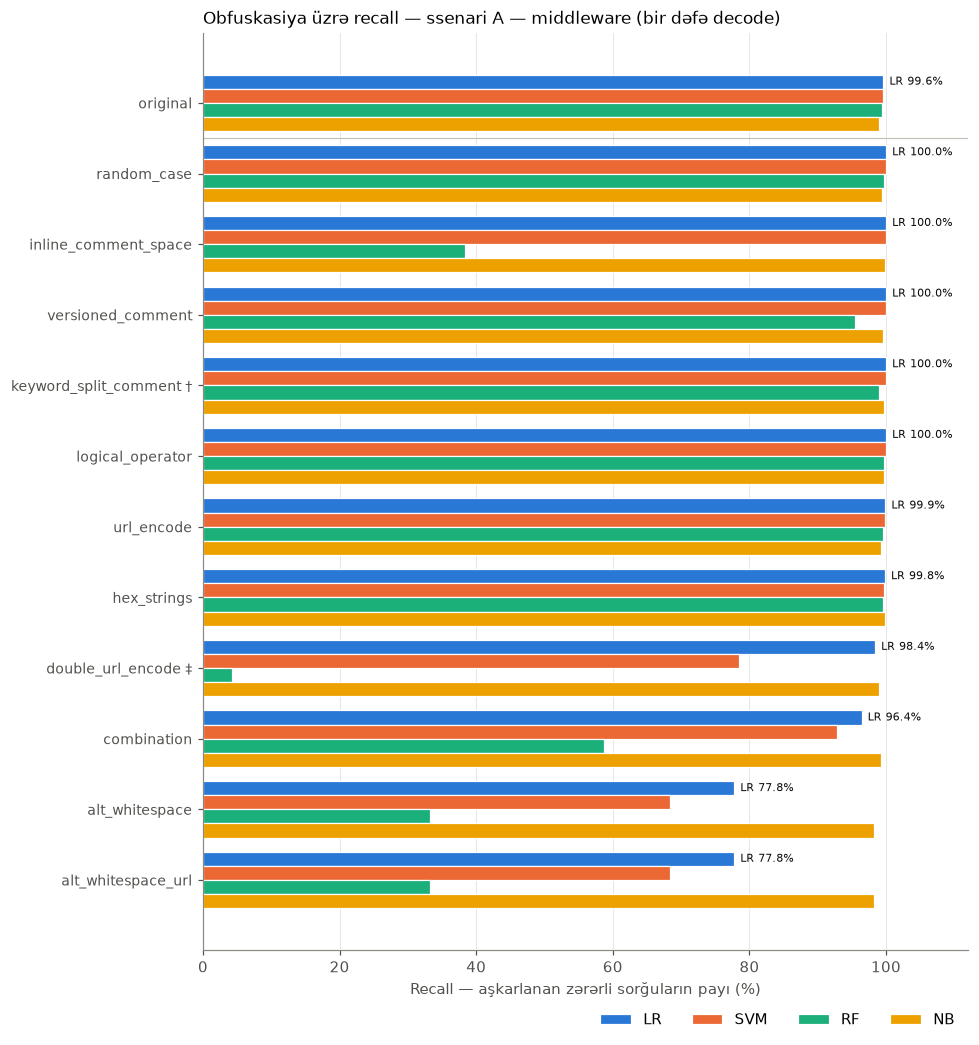

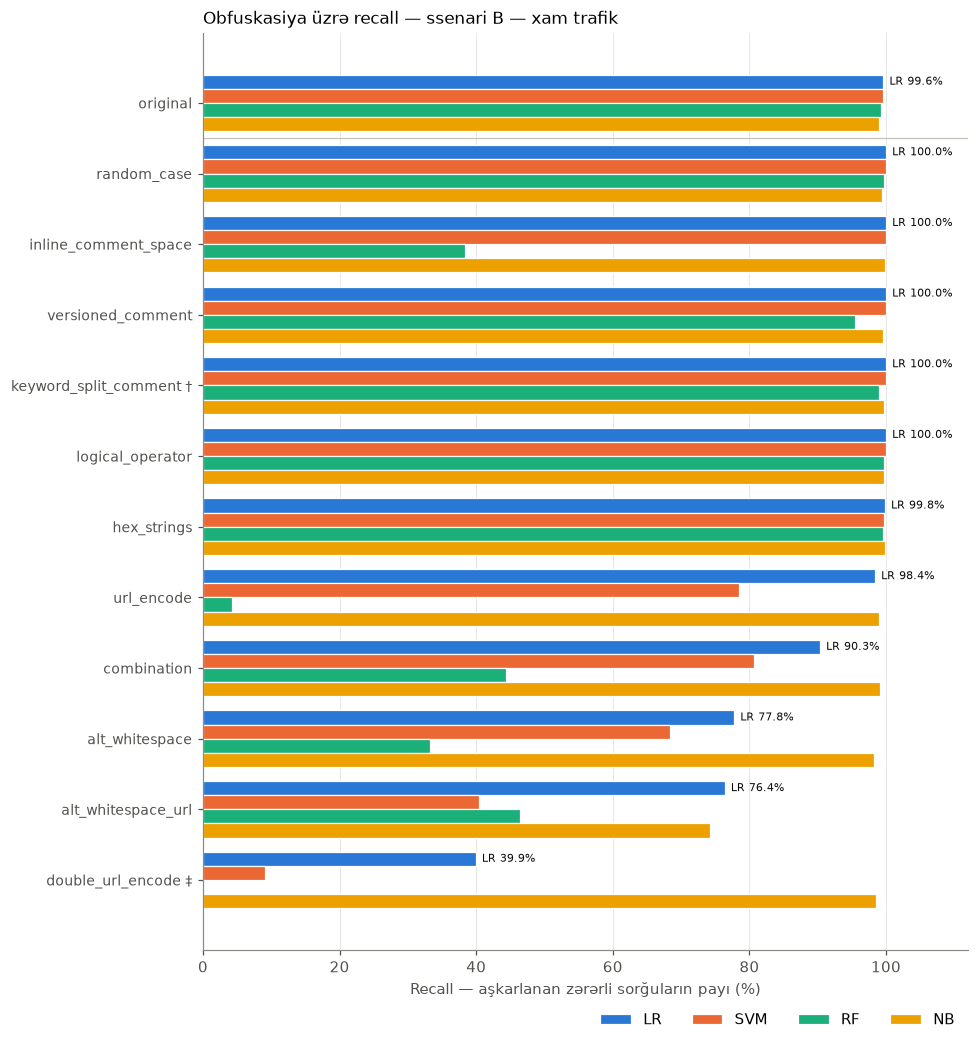

In [5]:
def mark(t):
    v = TECH_VALIDITY[t] if t in TECH_VALIDITY else "yes"
    return t + (" †" if v == "no" else " ‡" if v == "conditional" else "")

def plot_recall(table, title, fname):
    order = ["original"] + table.drop(index="original").sort_values("LR", ascending=False).index.tolist()
    y = np.arange(len(order))[::-1]
    h = 0.2
    fig, ax = plt.subplots(figsize=(9, 9.5))
    for k, m in enumerate(MODELS):
        vals = table.loc[order, m].to_numpy() * 100
        ax.barh(y + (1.5 - k) * h, vals, height=h, color=MODEL_COLORS[m], label=m,
                edgecolor="white", linewidth=0.8)
    for yi, t in zip(y, order):
        v = table.loc[t, "LR"] * 100
        ax.annotate(f"LR {v:.1f}%", (v, yi + 1.5 * h), xytext=(4, 0), textcoords="offset points",
                    va="center", fontsize=7.5, color="#0b0b0b")
    ax.set_yticks(y, [mark(t) for t in order], fontsize=9)
    ax.set_xlim(0, 112)
    ax.set_xticks(range(0, 101, 20))
    ax.set_xlabel("Recall — aşkarlanan zərərli sorğuların payı (%)")
    ax.set_title(title, loc="left", fontsize=11)
    ax.grid(axis="y", visible=False)
    ax.axhline(y[0] - 0.5, color="#c3c2b7", linewidth=0.8)
    ax.legend(frameon=False, loc="lower right", ncol=4, bbox_to_anchor=(1, -0.1))
    fig.tight_layout()
    save_fig(fig, fname)
    plt.show()

for sc, title in SCENARIOS.items():
    plot_recall(recall_tables[sc], f"Obfuskasiya üzrə recall — ssenari {title}", f"03_obfuscation_recall_{sc}.png")

## 5. Hər texnikadan nümunə
Hər texnika üçün bir təsadüfi payload (seed = 42): orijinal, obfuskasiya olunmuş forma və LR-in zərərli olma
ehtimalı — orijinal → ssenari A → ssenari B.

In [6]:
pA = long_df[long_df.scenario == "A"].set_index(["technique", "index"])["p_lr_after"]
pB = long_df[long_df.scenario == "B"].set_index(["technique", "index"])["p_lr_after"]
examples = (obf_df.groupby("technique", sort=False).sample(1, random_state=SEED)
            .set_index("technique").loc[TECH_ORDER].reset_index())
examples["p_lr_original"] = examples["original"].map(lambda q: lr.predict_proba([q])[0, 1])
examples["p_lr_A"] = [pA[(t, i)] for t, i in zip(examples.technique, examples["index"])]
examples["p_lr_B"] = [pB[(t, i)] for t, i in zip(examples.technique, examples["index"])]
examples[["technique", "techniques", "mysql_valid", "original", "obfuscated",
          "p_lr_original", "p_lr_A", "p_lr_B"]].to_csv(RES_DIR / "03_examples.csv", index=False)
for _, r in examples.iterrows():
    extra = f"  [{r.techniques}]" if r.technique == "combination" else ""
    print(f"== {r.technique}{extra}  (mysql_valid={r.mysql_valid})")
    print(f"   orijinal : {r.original[:150]!r}")
    print(f"   obfusk.  : {r.obfuscated[:150]!r}")
    print(f"   LR p     : orijinal {r.p_lr_original:.3f} | A {r.p_lr_A:.3f} | B {r.p_lr_B:.3f}")

== random_case  (mysql_valid=yes)
   orijinal : '-3960"   )    )    union all select 7813,7813,7813,7813,7813,7813--'
   obfusk.  : '-3960"   )    )    Union aLl SeLEcT 7813,7813,7813,7813,7813,7813--'
   LR p     : orijinal 0.999 | A 0.999 | B 0.999
== inline_comment_space  (mysql_valid=yes)
   orijinal : "1'||  (  select 'dfmw' from dual where 1723  =  1723"
   obfusk.  : "1'||/**/(/**/select/**/'dfmw'/**/from/**/dual/**/where/**/1723/**/=/**/1723"
   LR p     : orijinal 0.996 | A 0.981 | B 0.981
== alt_whitespace  (mysql_valid=yes)
   orijinal : "-7238%' or make_set  (  5375  =  9563,9563  )   and '%'  =  '"
   obfusk.  : "-7238%'\nor\x0cmake_set\x0c(\x0c5375\t=\n9563,9563\n)\x0cand\x0b'%'\x0b=\x0b'"
   LR p     : orijinal 1.000 | A 0.896 | B 0.896
== alt_whitespace_url  (mysql_valid=yes)
   orijinal : '1   )    )    as rbcf where 1053  =  1053'
   obfusk.  : '1%0a)%0a)%09as%09rbcf%0awhere%0a1053%0d=%091053'
   LR p     : orijinal 0.996 | A 0.047 | B 0.062
== url_encode  (mysql_vali

## 6. Recall-u ən çox düşən 3 texnika (ssenari A): hansı n-gram-lar itir?
LR xətti modeldir, ona görə qərar `logit = Σ tfidf(n-gram) · w(n-gram) + b` kimi parçalanır.
Hər n-gram üçün orijinal və obfuskasiya olunmuş sorğulardakı **töhfəni** (tfidf · w) müqayisə edirik
(texnikanın bütün sətirləri üzrə orta):
- **itən zərərli siqnal** — müsbət çəkili (zərərli) n-gram-lar, obfuskasiyadan sonra azalıb/yox olub
- **yaranan təmiz siqnal** — mənfi çəkili (təmiz) n-gram-lar, obfuskasiyadan sonra yaranıb/artıb

Qeyd: TF-IDF vektorlaşdırıcısı `lowercase=True` ilə öyrədildiyi üçün `random_case` modelə heç bir təsir göstərmir
(sorğular əvvəlcə kiçik hərfə çevrilir).

In [7]:
vec = lr.named_steps["tfidf"]
w = lr.named_steps["clf"].coef_[0]
vocab = np.array(vec.get_feature_names_out())

resA = results[(results.scenario == "A") & (results.model == "LR") & (results.technique != "original")]
top3 = resA.sort_values("drop_pp", ascending=False).head(3)["technique"].tolist()
print("Ssenari A-da recall-u ən çox düşən 3 texnika (LR):", top3)

loss_tables = {}
for tech in top3:
    sub = long_df[(long_df.scenario == "A") & (long_df.technique == tech)]
    Xo = vec.transform(sub["original_input"])
    Xa = vec.transform(sub["model_input"])
    contrib_o = np.asarray(Xo.mean(axis=0)).ravel() * w
    contrib_a = np.asarray(Xa.mean(axis=0)).ravel() * w
    delta = contrib_o - contrib_a  # > 0: logit bu n-gram hesabına azalıb
    t = pd.DataFrame({"ngram": vocab, "weight": w, "contrib_before": contrib_o,
                      "contrib_after": contrib_a, "logit_loss": delta})
    lost = t[(t.weight > 0) & (t.logit_loss > 0)].nlargest(12, "logit_loss").assign(kind="itən zərərli siqnal")
    gained = t[(t.weight < 0) & (t.logit_loss > 0)].nlargest(8, "logit_loss").assign(kind="yaranan təmiz siqnal")
    tab = pd.concat([lost, gained])
    tab.to_csv(RES_DIR / f"03_ngram_loss_A_{tech}.csv", index=False)
    loss_tables[tech] = tab

    logit_o = lr.decision_function(sub["original_input"]).mean()
    logit_a = lr.decision_function(sub["model_input"]).mean()
    print(f"\n===== {tech}: orta logit {logit_o:+.2f} → {logit_a:+.2f} =====")
    show = tab[["kind", "ngram", "weight", "contrib_before", "contrib_after", "logit_loss"]].copy()
    show["ngram"] = show["ngram"].map(repr)
    display(show.round(4))

Ssenari A-da recall-u ən çox düşən 3 texnika (LR): ['alt_whitespace', 'alt_whitespace_url', 'combination']



===== alt_whitespace: orta logit +11.62 → +2.58 =====


,kind,ngram,weight,contrib_before,contrib_after,logit_loss
0,itən zərərli siqnal,' ',12.1820,0.6507,0.0000,0.6507
5131,itən zərərli siqnal,' =',10.8997,0.2582,0.0000,0.2582
5132,itən zərərli siqnal,' = ',10.8997,0.2582,0.0000,0.2582
34678,itən zərərli siqnal,'= ',10.8997,0.2582,0.0000,0.2582
2126,itən zərərli siqnal,' )',6.8333,0.2323,0.0000,0.2323
2127,itən zərərli siqnal,' ) ',6.8333,0.2323,0.0000,0.2323
14187,itən zərərli siqnal,') ',6.8333,0.2323,0.0000,0.2323
2134,itən zərərli siqnal,' ) )',7.0752,0.1551,0.0000,0.1551
2135,itən zərərli siqnal,' ) ) ',7.0752,0.1551,0.0000,0.1551
14213,itən zərərli siqnal,') )',7.0752,0.1551,0.0000,0.1551



===== alt_whitespace_url: orta logit +11.62 → +2.58 =====


,kind,ngram,weight,contrib_before,contrib_after,logit_loss
0,itən zərərli siqnal,' ',12.1820,0.6507,0.0000,0.6507
5131,itən zərərli siqnal,' =',10.8997,0.2582,0.0000,0.2582
5132,itən zərərli siqnal,' = ',10.8997,0.2582,0.0000,0.2582
34678,itən zərərli siqnal,'= ',10.8997,0.2582,0.0000,0.2582
2126,itən zərərli siqnal,' )',6.8333,0.2323,0.0000,0.2323
2127,itən zərərli siqnal,' ) ',6.8333,0.2323,0.0000,0.2323
14187,itən zərərli siqnal,') ',6.8333,0.2323,0.0000,0.2323
2134,itən zərərli siqnal,' ) )',7.0752,0.1551,0.0000,0.1551
2135,itən zərərli siqnal,' ) ) ',7.0752,0.1551,0.0000,0.1551
14213,itən zərərli siqnal,') )',7.0752,0.1551,0.0000,0.1551



===== combination: orta logit +11.65 → +7.06 =====


,kind,ngram,weight,contrib_before,contrib_after,logit_loss
0,itən zərərli siqnal,' ',12.1820,0.6478,0.2450,0.4028
5131,itən zərərli siqnal,' =',10.8997,0.2583,0.1026,0.1556
5132,itən zərərli siqnal,' = ',10.8997,0.2583,0.1026,0.1556
34678,itən zərərli siqnal,'= ',10.8997,0.2583,0.1026,0.1556
2126,itən zərərli siqnal,' )',6.8333,0.2329,0.0882,0.1446
2127,itən zərərli siqnal,' ) ',6.8333,0.2329,0.0882,0.1446
14187,itən zərərli siqnal,') ',6.8333,0.2329,0.0882,0.1446
71628,itən zərərli siqnal,'or ',9.6521,0.1161,0.0124,0.1036
74716,itən zərərli siqnal,'r ',7.8794,0.1308,0.0272,0.1036
2134,itən zərərli siqnal,' ) )',7.0752,0.1555,0.0579,0.0976


Ən çox düşən 3 texnika üçün itən zərərli n-gram-ların vizual müqayisəsi (orta logit itkisi).

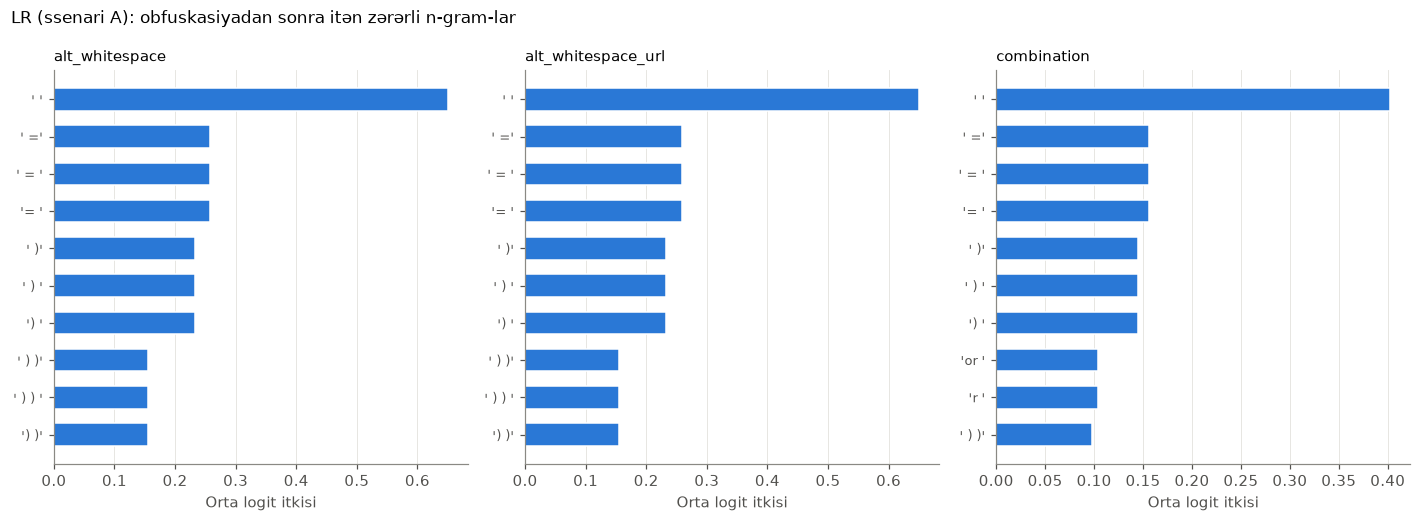

In [8]:
fig, axes = plt.subplots(1, len(top3), figsize=(13, 4.8))
for ax, tech in zip(np.atleast_1d(axes), top3):
    t = loss_tables[tech]
    t = t[t.kind == "itən zərərli siqnal"].head(10).iloc[::-1]
    ax.barh([repr(s) for s in t["ngram"]], t["logit_loss"], color="#2a78d6", height=0.6,
            edgecolor="white", linewidth=1)
    ax.set_title(tech, loc="left", fontsize=10)
    ax.set_xlabel("Orta logit itkisi")
    ax.tick_params(axis="y", labelsize=8.5)
    ax.grid(axis="y", visible=False)
fig.suptitle("LR (ssenari A): obfuskasiyadan sonra itən zərərli n-gram-lar", x=0.01, ha="left", fontsize=11)
fig.tight_layout()
save_fig(fig, "03_ngram_loss_top3.png")
plt.show()